# Análisis exploratorio de Olist (LAB-116, F8-01)

Este notebook explora los datos de Olist que cargó LAB-17 en los esquemas `orders` y `catalog`, para **conocer su calidad**
y **validar los valores** que usan el corpus de políticas (LAB-18) y las herramientas del chat (LAB-41). Lee directamente de
la base de datos, en **solo lectura**: no copia ningún CSV al repositorio ni modifica nada. La lógica vive en el paquete
`olist_eda` (probado); el notebook la orquesta y la interpreta.

Se ejecuta de arriba abajo sin editar nada con la base local de `docker compose` y Olist cargado (ver `ml/README.md`).

## 0. Parámetros

Todos los parámetros están en la **siguiente celda**. Se leen de variables de entorno y, si no existen, usan los valores
locales de `infra/docker-compose.yml`:

| Parámetro | Variable | Para qué sirve |
|---|---|---|
| `postgres_url`, `postgres_user`, `postgres_password` | `POSTGRES_URL`, `POSTGRES_USER`, `POSTGRES_PASSWORD` | Conexión de solo lectura a la base local (la contraseña no se muestra) |
| `min_group_orders` | `EDA_MIN_GROUP_ORDERS` | Pedidos mínimos para que un estado o una categoría entre en el ranking de retrasos |
| `kb_dir` | `KB_DIR` | Corpus de políticas que se contrasta con los datos |
| `top_n` | — | Filas de los rankings de retraso por estado y por categoría |
| estados de la consulta de pedidos | — | `ml/notebooks/data/order-tool-states.toml`: los estados que mostrará LAB-41 (hoy, los del corpus) |

In [1]:
# Parámetros del análisis: todos en esta celda. Ver la tabla anterior para qué hace cada uno.
%matplotlib inline
import numpy as np
import pandas as pd

from olist_eda import categorical, db, delivery, findings, integrity, policies, profiling, report
from olist_eda.config import NOTEBOOK_DATA_DIR, NOTEBOOK_RESULTS_DIR, AnalysisSettings
from olist_eda.schema import TABLES

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

settings = AnalysisSettings.from_env()
print(settings.describe())

{'base de datos': 'shoplab', 'usuario': 'shoplab', 'min_group_orders': 30, 'kb_dir': 'data/kb', 'top_n': 10}


## 1. Preflight

Antes de calcular nada se comprueba que la base de datos es alcanzable, que existen las ocho tablas y que ninguna está
vacía. Si algo falta, esta celda se detiene con un mensaje que dice qué hacer, y **no se ejecuta nada más**.

In [2]:
db.preflight(settings)
print("Preflight correcto: la base es alcanzable y las ocho tablas tienen datos.")

Preflight correcto: la base es alcanzable y las ocho tablas tienen datos.


## 2. Carga de datos

Cada tabla se lee con un `SELECT` en una conexión de **solo lectura** y se convierte a un `DataFrame` de Pandas. El cruce
entre `orders` y `catalog` se hace más adelante en Pandas, no en SQL: LAB-17 no deja claves foráneas entre esquemas.

In [3]:
with db.connect(settings) as connection:
    tables = db.load_tables(connection)

sizes = pd.DataFrame(
    {"tabla": list(tables), "filas": [len(frame) for frame in tables.values()], "columnas": [frame.shape[1] for frame in tables.values()]}
)
scale = report.data_scale(len(tables["orders.orders"]))
if scale == "sample":
    print("⚠ volumen reducido: muestra de pruebas (menos de 1 000 pedidos). Las cifras no son las del dataset completo.")
sizes.assign(filas=sizes["filas"].map(report.format_int))

,tabla,filas,columnas
0,orders.customers,"99,441",5
1,orders.orders,"99,441",8
2,orders.order_items,"112,650",7
3,orders.order_payments,"103,886",5
4,orders.order_reviews,"99,224",8
5,catalog.product_categories,73,2
6,catalog.products,"32,951",11
7,catalog.sellers,"3,095",4


## 3. Calidad por tabla

Cada tabla se perfila con operaciones **vectorizadas** de Pandas y NumPy sobre columnas completas (sin recorrer filas):

- **Nulos**: cantidad y porcentaje por columna, separados en *esperados* e *inesperados*. Un nulo es **esperado** cuando el
  negocio lo explica: un pedido `canceled` no se entrega, una reseña no obliga a escribir comentario, una categoría puede no
  tener traducción. Es **inesperado** cuando nada lo justifica (un pedido `delivered` sin fecha de entrega, un producto sin
  categoría). Una columna sin regla declarada trata **todo** nulo como inesperado, para que un problema nuevo no pase
  inadvertido. Las reglas están en `olist_eda/schema.py`.
- **Duplicados**: por **clave natural** y por **fila completa** (sin la columna sustituta `id`). No son lo mismo: el origen no
  garantiza `review_id` único, y un pedido puede tener varios pagos o varias reseñas. Se mide la diferencia en lugar de
  suponerla.
- **Tipos y rangos**: tipo de cada columna y, en las numéricas y de fecha, mínimo, máximo y percentiles (`p01`, `p50`, `p99`).
  **Implausibles** son los valores fuera de lo razonable: precio o peso en cero, flete negativo, puntuación fuera de 1–5 y
  fechas fuera de 2016–2018.

In [4]:
profiles = profiling.profile_tables(tables)

summary = pd.DataFrame(
    {
        "tabla": list(profiles),
        "filas": [p.rows for p in profiles.values()],
        "duplicados por clave": [p.key_duplicates for p in profiles.values()],
        "duplicados de fila completa": [p.row_duplicates for p in profiles.values()],
        "nulos inesperados": [sum(c.unexpected_null_count for c in p.columns) for p in profiles.values()],
        "valores implausibles": [sum(c.implausible_count for c in p.columns) for p in profiles.values()],
    }
)
summary

,tabla,filas,duplicados por clave,duplicados de fila completa,nulos inesperados,valores implausibles
0,orders.customers,99441,0,0,0,0
1,orders.orders,99441,0,0,24,0
2,orders.order_items,112650,0,0,0,4
3,orders.order_payments,103886,0,0,0,0
4,orders.order_reviews,99224,814,0,0,0
5,catalog.product_categories,73,0,0,0,0
6,catalog.products,32951,0,0,2448,4
7,catalog.sellers,3095,0,0,0,0


### 3.1 `orders.customers`

`customer_unique_id` identifica a la persona y `customer_id` a cada compra: una persona con varias compras repite `customer_unique_id`. No es un defecto.

In [5]:
print(report.table_headline(profiles["orders.customers"]))
report.profile_view(profiles["orders.customers"])

orders.customers: 99,441 filas · duplicados por clave: 0 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,customer_id,str,0,0.0,0,—,—,—,—,—,0
1,customer_unique_id,str,0,0.0,0,—,—,—,—,—,0
2,zip_code_prefix,str,0,0.0,0,—,—,—,—,—,0
3,city,str,0,0.0,0,—,—,—,—,—,0
4,state,str,0,0.0,0,—,—,—,—,—,0


### 3.2 `orders.orders`

Las fechas dependen del estado: la regla de nulos esperados mira `status` (una entrega nula es normal salvo en `delivered`).

In [6]:
print(report.table_headline(profiles["orders.orders"]))
report.profile_view(profiles["orders.orders"])

orders.orders: 99,441 filas · duplicados por clave: 0 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,order_id,str,0,0.00,0,—,—,—,—,—,0
1,customer_id,str,0,0.00,0,—,—,—,—,—,0
2,status,str,0,0.00,0,—,—,—,—,—,0
3,purchased_at,datetime64[us],0,0.00,0,2016-09-04,2017-01-29,2018-01-18,2018-08-20,2018-10-17,0
4,approved_at,datetime64[us],160,0.16,14,2016-09-15,2017-01-30,2018-01-19,2018-08-21,2018-09-03,0
5,delivered_to_carrier_at,datetime64[us],1783,1.79,2,2016-10-08,2017-02-02,2018-01-24,2018-08-22,2018-09-11,0
6,delivered_to_customer_at,datetime64[us],2965,2.98,8,2016-10-11,2017-02-10,2018-02-02,2018-08-28,2018-10-17,0
7,estimated_delivery_at,datetime64[us],0,0.00,0,2016-09-30,2017-03-06,2018-02-15,2018-09-10,2018-11-12,0


### 3.3 `orders.order_items`

Un pedido tiene uno o más ítems; `product_id` y `seller_id` apuntan a `catalog` **sin clave foránea** (ver sección 4).

In [7]:
print(report.table_headline(profiles["orders.order_items"]))
report.profile_view(profiles["orders.order_items"])

orders.order_items: 112,650 filas · duplicados por clave: 0 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,order_id,str,0,0.0,0,—,—,—,—,—,0
1,item_number,Int64,0,0.0,0,1.00,1.00,1.00,4.00,21.00,0
2,product_id,str,0,0.0,0,—,—,—,—,—,0
3,seller_id,str,0,0.0,0,—,—,—,—,—,0
4,shipping_limit_at,datetime64[us],0,0.0,0,2016-09-19,2017-02-02,2018-01-26,2018-08-24,2020-04-09,4
5,price,float64,0,0.0,0,0.85,9.99,74.99,890.00,6735.00,0
6,freight_value,float64,0,0.0,0,0.00,4.42,16.26,84.52,409.68,0


### 3.4 `orders.order_payments`

Un pedido puede tener varios pagos (`payment_sequence`); `payment_type` se analiza en la sección 5.

In [8]:
print(report.table_headline(profiles["orders.order_payments"]))
report.profile_view(profiles["orders.order_payments"])

orders.order_payments: 103,886 filas · duplicados por clave: 0 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,order_id,str,0,0.0,0,—,—,—,—,—,0
1,payment_sequence,Int64,0,0.0,0,1.00,1.00,1.00,3.00,29.00,0
2,payment_type,str,0,0.0,0,—,—,—,—,—,0
3,installments,Int64,0,0.0,0,0.00,1.00,1.00,10.00,24.00,0
4,payment_value,float64,0,0.0,0,0.00,6.69,100.00,1039.92,13664.08,0


### 3.5 `orders.order_reviews`

`review_id` **no es único en el origen**: por eso se distinguen los duplicados por clave de los de fila completa.

In [9]:
print(report.table_headline(profiles["orders.order_reviews"]))
report.profile_view(profiles["orders.order_reviews"])

orders.order_reviews: 99,224 filas · duplicados por clave: 814 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,id,Int64,0,0.00,0,1.00,993.23,49612.50,98231.77,99224.00,0
1,review_id,str,0,0.00,0,—,—,—,—,—,0
2,order_id,str,0,0.00,0,—,—,—,—,—,0
3,score,Int64,0,0.00,0,1.00,1.00,5.00,5.00,5.00,0
4,comment_title,str,87658,88.34,0,—,—,—,—,—,0
5,comment_message,str,58274,58.73,0,—,—,—,—,—,0
6,created_at,datetime64[us],0,0.00,0,2016-10-02,2017-02-11,2018-02-02,2018-08-29,2018-08-31,0
7,answered_at,datetime64[us],0,0.00,0,2016-10-07,2017-02-13,2018-02-04,2018-08-31,2018-10-29,0


### 3.6 `catalog.product_categories`

Una categoría sin traducción tiene `name_en` nulo: es un nulo esperado del origen.

In [10]:
print(report.table_headline(profiles["catalog.product_categories"]))
report.profile_view(profiles["catalog.product_categories"])

catalog.product_categories: 73 filas · duplicados por clave: 0 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,name,str,0,0.00,0,—,—,—,—,—,0
1,name_en,str,2,2.74,0,—,—,—,—,—,0


### 3.7 `catalog.products`

`reference_price` se deriva de `order_items` y `stock` es sintético (ver `docs/olist-dataset.md`): no son datos del origen.

In [11]:
print(report.table_headline(profiles["catalog.products"]))
report.profile_view(profiles["catalog.products"])

catalog.products: 32,951 filas · duplicados por clave: 0 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,product_id,str,0,0.00,0,—,—,—,—,—,0
1,category_name,str,610,1.85,610,—,—,—,—,—,0
2,name_length,Int64,610,1.85,610,5.00,20.00,51.00,63.00,76.00,0
3,description_length,Int64,610,1.85,610,4.00,84.00,595.00,3286.20,3992.00,0
4,photos_count,Int64,610,1.85,610,1.00,1.00,1.00,8.00,20.00,0
5,weight_g,Int64,2,0.01,2,0.00,60.00,700.00,22538.00,40425.00,4
6,length_cm,Int64,2,0.01,2,7.00,16.00,25.00,100.00,105.00,0
7,height_cm,Int64,2,0.01,2,2.00,2.00,13.00,69.00,105.00,0
8,width_cm,Int64,2,0.01,2,6.00,11.00,20.00,63.00,118.00,0
9,reference_price,float64,0,0.00,0,0.85,9.60,79.00,1199.00,6735.00,0


### 3.8 `catalog.sellers`

Tabla de referencia, sin dependencias.

In [12]:
print(report.table_headline(profiles["catalog.sellers"]))
report.profile_view(profiles["catalog.sellers"])

catalog.sellers: 3,095 filas · duplicados por clave: 0 · duplicados de fila completa: 0


,columna,tipo,nulos,% nulos,nulos inesperados,mín,p01,p50,p99,máx,implausibles
0,seller_id,str,0,0.0,0,—,—,—,—,—,0
1,zip_code_prefix,str,0,0.0,0,—,—,—,—,—,0
2,city,str,0,0.0,0,—,—,—,—,—,0
3,state,str,0,0.0,0,—,—,—,—,—,0


## 4. Integridad entre esquemas

LAB-17 dejó `orders` y `catalog` **sin claves foráneas entre sí** para que puedan extraerse como servicios: un ítem de pedido
referencia el producto y el vendedor solo por id. Eso significa que la base **no impide** un ítem huérfano, así que esta
es la única comprobación de integridad que existirá entre ambos esquemas. El cruce se hace en Pandas con `isin`.

In [13]:
orphans = pd.DataFrame(
    [
        {"referencia": o.reference, "revisadas": o.checked, "huérfanas": o.orphans, "% huérfanas": round(o.pct, 4)}
        for o in integrity.orphan_references(tables)
    ]
)
orphans

,referencia,revisadas,huérfanas,% huérfanas
0,order_items.product_id -> catalog.products,112650,0,0.0
1,order_items.seller_id -> catalog.sellers,112650,0,0.0
2,products.category_name -> product_categories,32341,0,0.0


Repeticiones que el origen permite a propósito y que **no son defectos** (se muestran solo para dimensionarlas):

In [14]:
pd.Series(profiling.informative_repetitions(tables), name="cantidad").to_frame()

,cantidad
persons_with_several_customer_ids,2997
orders_with_several_reviews,547


## 5. Tipos de pago

`payment_type` se cuenta **por pago**, no por pedido: un pedido puede tener varios pagos (`payment_sequence`), por ejemplo
una parte con tarjeta y otra con un vale. Cada valor se contrasta con las políticas de dos formas: si la **declara** la tabla
canónica de su política («Nombre en el pedido» de `payments-01-payment-methods`) y en qué documentos del corpus se **cita**
entre comillas invertidas.

In [15]:
observed = set(tables["orders.order_payments"]["payment_type"]) | set(tables["orders.orders"]["status"])
reference = policies.load_policy_reference(settings.kb_dir, observed)
tool = categorical.load_order_tool_states(NOTEBOOK_DATA_DIR / "order-tool-states.toml")
frequencies = categorical.value_frequencies(tables, reference, tool)

print(f"{len(frequencies['payment_type'])} tipos de pago distintos en {len(tables['orders.order_payments']):,} pagos.")
categorical.frequencies_frame(frequencies["payment_type"])

5 tipos de pago distintos en 103,886 pagos.

,valor,cantidad,%,declarado por la política,citado en
0,credit_card,76795,73.92,sí,"payments-01-payment-methods, payments-02-insta..."
1,boleto,19784,19.04,sí,"payments-01-payment-methods, payments-03-bolet..."
2,voucher,5775,5.56,sí,"payments-01-payment-methods, payments-03-bolet..."
3,debit_card,1529,1.47,sí,"payments-01-payment-methods, payments-02-insta..."
4,not_defined,3,0.00,no,—


## 6. Estados del pedido

`order_status` se cuenta por pedido. La tabla marca si el estado lo **declara** la tabla «Estados del pedido» de
`shipping-03-order-tracking`, en qué documentos se **cita** y si lo **cubre** la consulta de pedidos que implementará LAB-41
(`order-tool-states.toml`).

In [16]:
print(f"{len(frequencies['order_status'])} estados distintos en {len(tables['orders.orders']):,} pedidos.")
categorical.frequencies_frame(frequencies["order_status"])

8 estados distintos en 99,441 pedidos.


,valor,cantidad,%,declarado por la política,citado en,cubierto por la consulta de pedidos
0,delivered,96478,97.02,sí,"returns-01-return-policy, returns-04-exchanges...",sí
1,shipped,1107,1.11,sí,"returns-04-exchanges-and-cancellations, return...",sí
2,canceled,625,0.63,sí,"payments-03-boleto-and-vouchers, payments-04-p...",sí
3,unavailable,609,0.61,sí,"returns-03-refunds, returns-04-exchanges-and-c...",sí
4,invoiced,314,0.32,sí,"returns-04-exchanges-and-cancellations, return...",sí
5,processing,301,0.30,sí,"returns-04-exchanges-and-cancellations, return...",sí
6,created,5,0.01,sí,"payments-01-payment-methods, payments-03-bolet...",sí
7,approved,2,0.00,sí,"payments-01-payment-methods, payments-03-bolet...",sí


## 7. Contraste con políticas y con la consulta de pedidos

El contraste se hace **en ambos sentidos**: valores de los datos que las políticas o la consulta de pedidos no cubren, y
valores que declaran y que no existen en los datos. Una discrepancia no es necesariamente un error: puede ser ruido o algo
que merezca documentarse. Esa decisión se toma en la sección 12.

**Valores de los datos que ninguna política declara ni cita:**

In [17]:
gaps = {column: categorical.uncovered_by_policies(items) for column, items in frequencies.items()}
rows = [categorical.frequencies_frame(items).assign(columna=column) for column, items in gaps.items() if items]
uncovered = pd.concat(rows, ignore_index=True) if rows else None
uncovered if uncovered is not None else print("Ningún valor de los datos queda sin cubrir por las políticas.")

,valor,cantidad,%,declarado por la política,citado en,columna
0,not_defined,3,0.0,no,—,payment_type


**Estados de los datos que la consulta de pedidos no cubre:**

In [18]:
not_covered = categorical.frequencies_frame(categorical.uncovered_by_tool(frequencies["order_status"]))
not_covered if not not_covered.empty else print("La consulta de pedidos cubre todos los estados de los datos.")

La consulta de pedidos cubre todos los estados de los datos.


**Valores que declaran las políticas o la consulta de pedidos y que no existen en los datos:**

In [19]:
absent = categorical.absent_values(tables, reference, tool)
pd.DataFrame(
    [
        ("payment_type", "políticas", ", ".join(absent.payment_type) or "—"),
        ("order_status", "políticas", ", ".join(absent.order_status_policy) or "—"),
        ("order_status", "consulta de pedidos (LAB-41)", ", ".join(absent.order_status_tool) or "—"),
    ],
    columns=["columna", "declarado por", "valores sin datos"],
)

,columna,declarado por,valores sin datos
0,payment_type,políticas,—
1,order_status,políticas,—
2,order_status,consulta de pedidos (LAB-41),—


**Un límite del contraste con LAB-41.** LAB-41 aún no está implementada ni define su propio conjunto de estados, así que
`order-tool-states.toml` copia la tabla de seguimiento del corpus. Mientras ambos coincidan, el contraste con la consulta de
pedidos **no aporta información nueva** respecto al contraste con las políticas. La siguiente celda lo comprueba:

In [20]:
if set(tool.states) == reference.declared_order_states:
    print("La consulta de pedidos usa exactamente los estados de la política: este contraste es el mismo que el anterior.")
else:
    print("La consulta de pedidos difiere de la política:",
          sorted(set(tool.states) ^ reference.declared_order_states))
print("Origen de la lista:", tool.source)

La consulta de pedidos usa exactamente los estados de la política: este contraste es el mismo que el anterior.
Origen de la lista: Tabla «Estados del pedido» de data/kb/shipping-03-order-tracking.md; LAB-41 no define otro conjunto todavía


## 8. Tiempos de entrega

Para cada pedido entregado se calcula el **tiempo real** (de la compra a la entrega al cliente), el **estimado** (de la compra
a la fecha estimada) y su diferencia. Un pedido tiene **retraso** cuando se entregó **después** de la fecha estimada.

Solo se analizan los pedidos con fecha de entrega y fechas coherentes. Todo pedido excluido se cuenta con **un único
motivo**, para que nada se oculte: sin fecha de entrega, entrega anterior a la compra o fecha estimada anterior a la compra.

In [21]:
deliveries = delivery.build_delivery_frame(tables)
exclusions = delivery.exclusion_counts(deliveries)
stats = delivery.time_statistics(deliveries)

print(f"{exclusions.analyzed:,} de {exclusions.total_orders:,} pedidos analizados.")
pd.DataFrame(
    [
        ("Analizados", exclusions.analyzed),
        ("Excluidos: sin fecha de entrega", exclusions.no_delivery_date),
        ("Excluidos: entrega anterior a la compra", exclusions.delivered_before_purchase),
        ("Excluidos: fecha estimada anterior a la compra", exclusions.estimated_before_purchase),
        ("Total", exclusions.total_orders),
    ],
    columns=["grupo", "pedidos"],
)

96,476 de 99,441 pedidos analizados.


,grupo,pedidos
0,Analizados,96476
1,Excluidos: sin fecha de entrega,2965
2,Excluidos: entrega anterior a la compra,0
3,Excluidos: fecha estimada anterior a la compra,0
4,Total,99441


Los pedidos **sin fecha de entrega**, por estado (lo esperable es que no estén `delivered`):

In [22]:
pd.Series(exclusions.no_delivery_date_by_status, name="pedidos").rename_axis("estado").to_frame()

,pedidos
estado,
approved,2
canceled,619
created,5
delivered,8
invoiced,314
processing,301
shipped,1107
unavailable,609


Dos incoherencias del origen que se informan aparte (no son un motivo de exclusión propio):

In [23]:
pd.DataFrame(
    [
        ("`delivered` sin fecha de entrega (ya incluidos en «sin fecha de entrega»)", exclusions.delivered_without_date),
        ("Fecha de entrega en un pedido cuyo estado no es `delivered`", exclusions.date_with_non_delivered_status),
    ],
    columns=["incoherencia", "pedidos"],
)

,incoherencia,pedidos
0,`delivered` sin fecha de entrega (ya incluidos...,8
1,Fecha de entrega en un pedido cuyo estado no e...,6


**Distribución** de los tiempos de los pedidos analizados, y qué fracción llegó antes, el mismo día o después de lo estimado:

,media,mediana,p95
tiempo real (días),12.56,10.22,29.28
tiempo estimado (días),23.74,23.23,38.42
real − estimado (días),-11.18,-11.95,3.82


Antes de lo estimado: 91.89 % · el mismo día: 0.00 % · después: 8.11 %


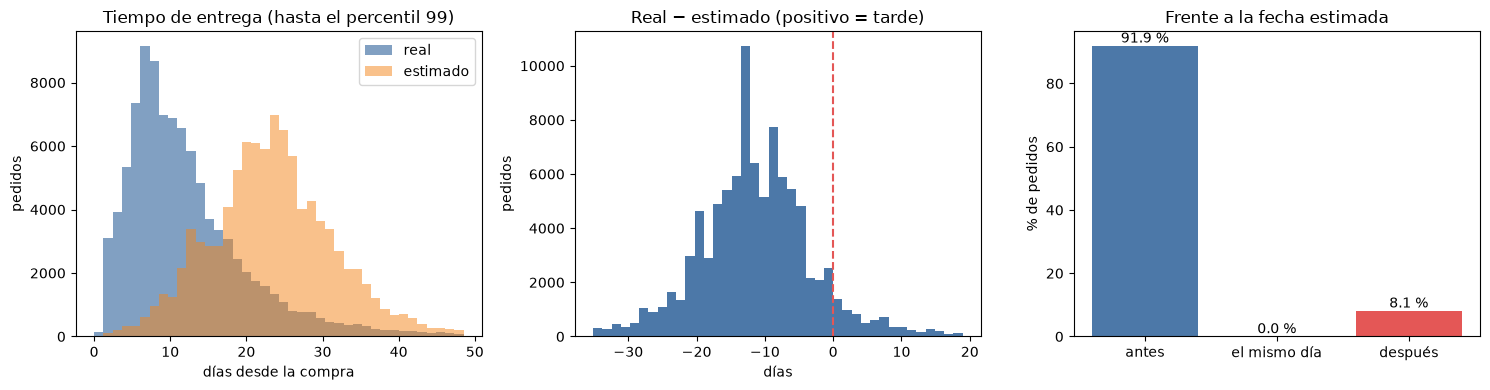

In [24]:
if stats.analyzed_orders == 0:
    print("Ningún pedido tiene fecha de entrega coherente: no hay tiempos que analizar.")
else:
    display(
        pd.DataFrame(
            {"tiempo real (días)": stats.actual_days, "tiempo estimado (días)": stats.estimated_days,
             "real − estimado (días)": stats.delay_days}
        ).T.round(2).rename(columns={"mean": "media", "median": "mediana", "p95": "p95"})
    )
    print(f"Antes de lo estimado: {report.format_pct(stats.early_pct / 100)} · "
          f"el mismo día: {report.format_pct(stats.same_day_pct / 100)} · "
          f"después: {report.format_pct(stats.late_pct / 100)}")
figure = report.plot_delivery_times(deliveries)
figure if figure is not None else print("Sin pedidos analizables: no hay gráfico.")

## 9. Retrasos por estado del cliente

Se resumen los pedidos entregados por **estado geográfico del cliente (UF)**: número de pedidos, retraso medio, porcentaje con retraso y puntuación
media de reseña. Un grupo con menos de `min_group_orders` pedidos (ver sección 0) **no entra al ranking**: con muy pocos
pedidos, un solo caso parecería una tendencia. Los grupos pequeños se muestran aparte.

Umbral: 30 pedidos por grupo · 27 grupos en el ranking · 0 grupos pequeños.


,grupo,pedidos,retraso medio (días),% con retraso,puntuación media
0,AL,397,-8.03,23.93,3.85
1,MA,717,-8.89,19.67,3.83
2,PI,476,-10.63,15.97,3.99
3,CE,1279,-10.11,15.32,3.94
4,SE,335,-9.33,15.22,3.91
5,BA,3256,-10.10,14.04,3.93
6,RJ,12353,-11.06,13.47,3.96
7,TO,274,-11.44,12.77,4.15
8,PA,946,-13.39,12.37,3.91
9,ES,1995,-9.80,12.23,4.08


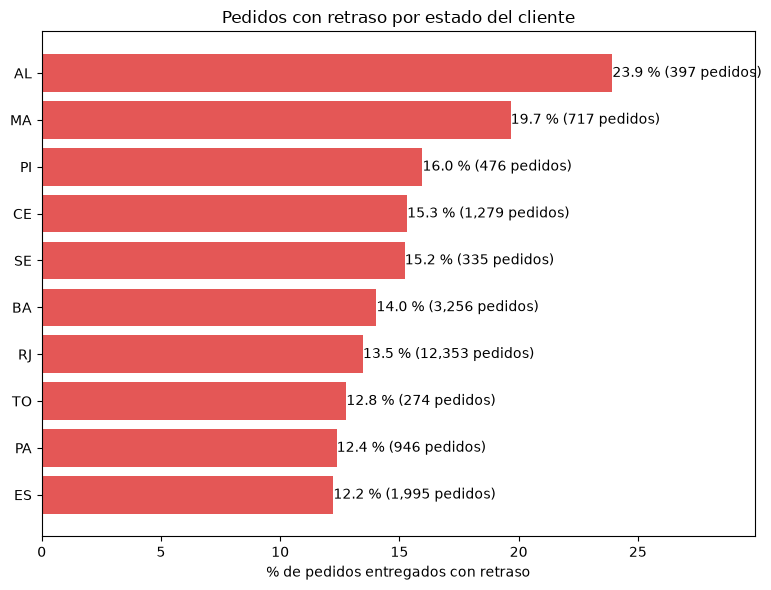

In [25]:
ranking, small = delivery.delay_summary(deliveries, "customer_state", settings.min_group_orders)
print(f"Umbral: {settings.min_group_orders} pedidos por grupo · {len(ranking)} grupos en el ranking · {len(small)} grupos pequeños.")
if ranking.empty:
    print("Ningún grupo alcanza el umbral: no hay ranking que mostrar.")
else:
    display(report.summary_view(ranking.head(settings.top_n)))
figure = report.plot_delay_ranking(ranking, "Pedidos con retraso por estado del cliente", settings.top_n)
figure if figure is not None else None

Grupos por debajo del umbral:

In [26]:
report.summary_view(small).head(10) if not small.empty else print("Todos los grupos alcanzan el umbral.")

Todos los grupos alcanzan el umbral.


## 10. Retrasos por categoría

Se resumen los pedidos entregados por **categoría de producto**: número de pedidos, retraso medio, porcentaje con retraso y puntuación
media de reseña. Un grupo con menos de `min_group_orders` pedidos (ver sección 0) **no entra al ranking**: con muy pocos
pedidos, un solo caso parecería una tendencia. Los grupos pequeños se muestran aparte.

**Criterio de categoría.** Un pedido puede tener productos de varias categorías. Para contarlo una sola vez se le asigna la
categoría de su **ítem de mayor precio** (a igualdad de precio, el de menor número de ítem). Se muestra el nombre en inglés y,
si la categoría no tiene traducción, el original; los pedidos sin categoría conocida aparecen como «sin categoría».

Umbral: 30 pedidos por grupo · 63 grupos en el ranking · 11 grupos pequeños.


,grupo,pedidos,retraso medio (días),% con retraso,puntuación media
0,furniture_mattress_and_upholstery,37,-6.48,13.51,3.89
1,audio,344,-9.33,13.08,3.85
2,fashion_underwear_beach,117,-9.78,12.82,4.01
3,books_technical,254,-10.54,11.02,4.42
4,home_confort,370,-9.08,10.27,3.92
5,food,436,-9.02,10.09,4.34
6,electronics,2502,-10.26,9.87,4.13
7,christmas_supplies,124,-11.46,9.68,4.11
8,baby,2761,-10.76,9.27,4.12
9,construction_tools_construction,724,-10.31,9.25,4.15


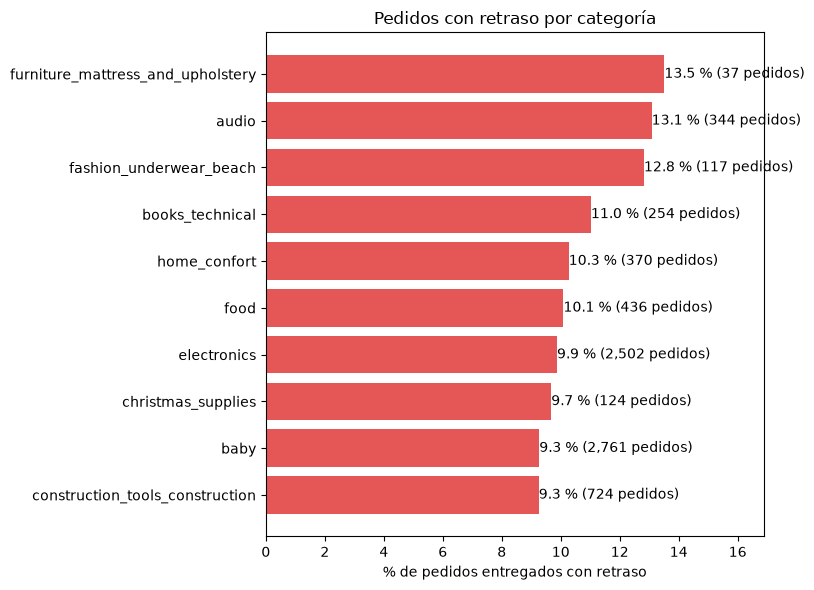

In [27]:
ranking, small = delivery.delay_summary(deliveries, "primary_category", settings.min_group_orders)
print(f"Umbral: {settings.min_group_orders} pedidos por grupo · {len(ranking)} grupos en el ranking · {len(small)} grupos pequeños.")
if ranking.empty:
    print("Ningún grupo alcanza el umbral: no hay ranking que mostrar.")
else:
    display(report.summary_view(ranking.head(settings.top_n)))
figure = report.plot_delay_ranking(ranking, "Pedidos con retraso por categoría", settings.top_n)
figure if figure is not None else None

Grupos por debajo del umbral:

In [28]:
report.summary_view(small).head(10) if not small.empty else print("Todos los grupos alcanzan el umbral.")

,grupo,pedidos,retraso medio (días),% con retraso,puntuación media
0,flowers,29,-11.17,3.45,4.39
1,diapers_and_hygiene,25,-11.76,4.00,3.96
2,fashion_sport,25,-11.42,8.00,4.44
3,arts_and_craftmanship,22,-6.07,9.09,4.32
4,home_comfort_2,22,-7.25,18.18,3.90
5,la_cuisine,13,-15.71,0.00,4.25
6,portateis_cozinha_e_preparadores_de_alimentos,13,-9.05,7.69,3.62
7,cds_dvds_musicals,12,-15.08,0.00,4.67
8,fashion_childrens_clothes,7,-14.99,0.00,5.00
9,pc_gamer,7,-10.07,0.00,3.43


In [29]:
multi = delivery.multicategory_orders(tables)
print(f"{multi:,} de {len(tables['orders.orders']):,} pedidos tienen productos de más de una categoría "
      f"({report.format_pct(multi / len(tables['orders.orders']))}): es el sesgo máximo de este criterio.")

786 de 99,441 pedidos tienen productos de más de una categoría (0.79 %): es el sesgo máximo de este criterio.

## 11. Reseñas

Distribución de la puntuación de las reseñas (1 a 5) y su relación con el retraso. Un pedido puede tener varias reseñas: para
compararlo con el retraso se usa la **media** de sus puntuaciones. Los tramos de retraso son: *a tiempo o antes*, *1 a 7 días
tarde* y *más de 7 días tarde*. La relación es **descriptiva**: no demuestra que el retraso cause la puntuación.

,reseñas,%
puntuación,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


,tramo,pedidos,puntuación media,mediana
0,a tiempo o antes,88649,4.29,5.0
1,1 a 7 días tarde,4481,3.18,4.0
2,más de 7 días tarde,3346,1.73,1.0


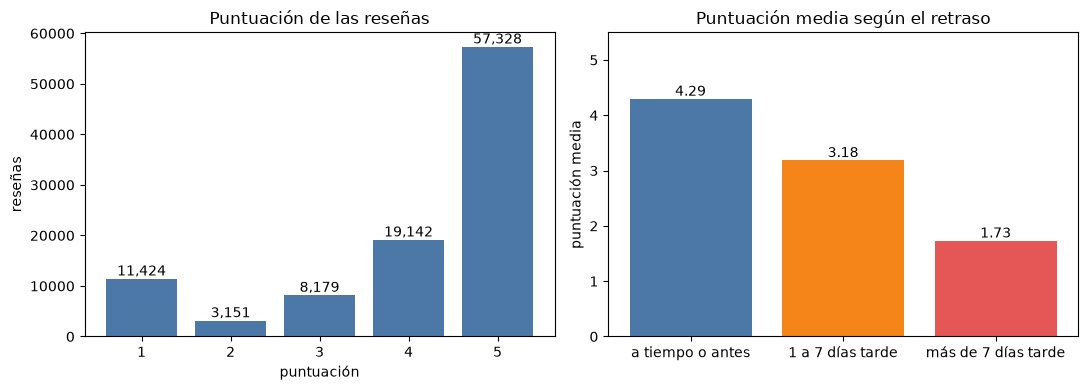

In [30]:
distribution = delivery.score_distribution(tables["orders.order_reviews"])
by_bucket = delivery.score_by_delay_bucket(deliveries)

display(pd.DataFrame({"reseñas": distribution, "%": (distribution / distribution.sum() * 100).round(2)}).rename_axis("puntuación"))
display(by_bucket.round(2).rename(columns={"bucket": "tramo", "orders": "pedidos", "mean_score": "puntuación media",
                                           "median_score": "mediana"}))
figure = report.plot_review_scores(distribution, by_bucket)
figure if figure is not None else print("Sin reseñas: no hay gráfico.")

## 12. Discrepancias y acciones

Cada discrepancia de las secciones anteriores se convierte en un **hallazgo** con su **origen** (tipo y sujeto), su
**impacto** en el chat, un **destino** (`corpus`, `LAB-41`, `loader`, `new_task` o `analysis_note`) y una **acción
propuesta**. La tabla la genera el código a partir de los datos: nada se escribe a mano aquí.

Las acciones salen de `ml/notebooks/data/discrepancy-actions.toml`: primero la regla específica del hallazgo y, si no hay,
la del tipo. **Si un hallazgo no tiene ninguna, esta celda falla**, de modo que ninguna discrepancia queda sin acción. Esto
**propone**: crear las tareas en Jira o editar el corpus es trabajo posterior a esta historia.

Los hallazgos son discrepancias, no necesariamente errores: algunos son ruido y la acción es dejarlo anotado.

In [31]:
actions = findings.load_actions(NOTEBOOK_DATA_DIR / "discrepancy-actions.toml")
found = findings.with_actions(findings.detect_findings(tables, reference, tool), actions)

print(f"{len(found)} hallazgos: " + ", ".join(
    f"{area} {sum(1 for f in found if f.area == key)}" for key, area in
    (("quality", "calidad"), ("values", "valores"), ("delivery", "entregas"))
))
with pd.option_context("display.max_colwidth", None):
    display(report.findings_view(found))

16 hallazgos: calidad 13, valores 1, entregas 2


,área,tipo,sujeto,cantidad,%,impacto,destino,acción
0,calidad,unexpected_nulls,catalog.products.category_name,610,1.85,610 nulos sin explicación en catalog.products.category_name: lo que dependa de esa columna queda incompleto.,new_task,"Abrir una tarea: 610 productos no tienen categoría, nombre, descripción ni fotos (son los mismos). Decidir si el catálogo los oculta o las respuestas los muestran como «sin categoría»."
1,calidad,unexpected_nulls,catalog.products.description_length,610,1.85,610 nulos sin explicación en catalog.products.description_length: lo que dependa de esa columna queda incompleto.,analysis_note,Son los mismos 610 productos sin categoría: se resuelve con la tarea de category_name y no requiere acción propia.
2,calidad,unexpected_nulls,catalog.products.name_length,610,1.85,610 nulos sin explicación en catalog.products.name_length: lo que dependa de esa columna queda incompleto.,analysis_note,Son los mismos 610 productos sin categoría: se resuelve con la tarea de category_name y no requiere acción propia.
3,calidad,unexpected_nulls,catalog.products.photos_count,610,1.85,610 nulos sin explicación en catalog.products.photos_count: lo que dependa de esa columna queda incompleto.,analysis_note,Son los mismos 610 productos sin categoría: se resuelve con la tarea de category_name y no requiere acción propia.
4,calidad,unexpected_nulls,orders.orders.approved_at,14,0.01,14 nulos sin explicación en orders.orders.approved_at: lo que dependa de esa columna queda incompleto.,LAB-41,14 pedidos `delivered` no tienen fecha de aprobación: la consulta de pedidos no debe depender de `approved_at` para mostrar el estado.
5,calidad,implausible_range,catalog.products.weight_g,4,0.01,4 valores implausibles en catalog.products.weight_g: distorsionan rangos y promedios.,new_task,"4 productos pesan 0 g: tratarlos como dato faltante en cualquier cálculo que use el peso (envío, modelado de F8)."
6,calidad,implausible_range,orders.order_items.shipping_limit_at,4,0.00,4 valores implausibles en orders.order_items.shipping_limit_at: distorsionan rangos y promedios.,loader,"4 ítems tienen fecha límite de envío en 2020, fuera de la ventana 2016-2018 del dataset: valorar que el cargador de LAB-17 los reporte. No afectan a los tiempos de entrega."
7,calidad,category_without_translation,catalog.product_categories.name_en,2,2.74,2 categorías no tienen traducción: el chat las mostraría con su nombre original.,loader,2 categorías sin traducción (pc_gamer y portateis_cozinha_e_preparadores_de_alimentos): el chat debe mostrar el nombre original; valorar añadir la traducción en el cargador.
8,calidad,unexpected_nulls,catalog.products.height_cm,2,0.01,2 nulos sin explicación en catalog.products.height_cm: lo que dependa de esa columna queda incompleto.,analysis_note,Son los mismos 2 productos sin peso: se resuelve con la tarea de weight_g y no requiere acción propia.
9,calidad,unexpected_nulls,catalog.products.length_cm,2,0.01,2 nulos sin explicación en catalog.products.length_cm: lo que dependa de esa columna queda incompleto.,analysis_note,Son los mismos 2 productos sin peso: se resuelve con la tarea de weight_g y no requiere acción propia.


Se guarda también un **resumen en JSON** con las cifras clave (`ml/notebooks/results/olist-eda-summary.json`). Solo se
escribe cuando los datos son los completos de Olist: una ejecución sobre la muestra de pruebas (CI) **no** lo sobrescribe.

In [32]:
summary = report.build_summary(
    tables, profiles=profiles, frequencies=frequencies, absent=absent, exclusions=exclusions, stats=stats,
    distribution=distribution, by_bucket=by_bucket, found=found,
)
if summary["data_scale"] == "full":
    report.write_summary(summary, NOTEBOOK_RESULTS_DIR / "olist-eda-summary.json")
    print("Resumen guardado en ml/notebooks/results/olist-eda-summary.json")
else:
    report.validate_summary(summary)
    print("Volumen reducido: el resumen se valida pero no se guarda.")

Resumen guardado en ml/notebooks/results/olist-eda-summary.json


## 13. Conclusiones

> **Cómo leer esta sección.** Las tablas y cifras de arriba las genera el código; **esta interpretación está escrita a mano**
> sobre la ejecución guardada, con el dataset completo de Olist (99,441 pedidos). Si cambian los datos o el corpus, vuelve a
> leerla: las cifras de aquí pueden dejar de ser ciertas aunque el notebook siga ejecutándose sin errores.

### Calidad de los datos

- **Las ocho tablas cargan completas** y cuadran con LAB-17: 99,441 clientes y pedidos, 112,650 ítems, 103,886 pagos, 99,224
  reseñas, 32,951 productos, 73 categorías y 3,095 vendedores.
- **Integridad entre esquemas: sin discrepancias.** Ningún ítem apunta a un producto o vendedor inexistente en `catalog` y
  ninguna categoría de producto falta en `product_categories` (0 huérfanos sobre 112,650, 112,650 y 32,341 filas revisadas). La
  ausencia de claves foráneas entre esquemas no ha provocado ningún huérfano.
- **Duplicados: sin filas repetidas** en ninguna tabla. Lo que sí se repite es propio del origen y no es un defecto: 814
  `review_id` repetidos (el origen no lo garantiza único), 547 pedidos con varias reseñas y 2,997 personas con más de un
  `customer_id`.
- **Nulos inesperados, pocos y muy concentrados.** 610 productos (1.85 %) no tienen categoría, nombre, descripción ni fotos, y son
  los mismos en las cuatro columnas; 2 productos no tienen peso ni medidas; 14 pedidos `delivered` no tienen fecha de aprobación,
  2 no tienen fecha de entrega al transportista y 8 no tienen fecha de entrega al cliente.
- **Rangos implausibles: dos casos menores.** 4 productos pesan 0 g y 4 ítems tienen una fecha límite de envío en 2020, fuera de la
  ventana 2016-2018 del dataset.

### Valores de pago y estado frente al corpus

- **`payment_type` tiene 5 valores**: `credit_card` (73.92 %), `boleto` (19.04 %), `voucher` (5.56 %), `debit_card` (1.47 %) y
  `not_defined` (3 pagos). Los cuatro que declara la política de pagos existen en los datos. **`not_defined` no lo declara ni lo
  cita ninguna política**: son 3 pagos de importe cero en pedidos `canceled`, es ruido y la acción es documentarlo o ignorarlo.
- **`order_status` tiene 8 valores y coinciden exactamente con los 8 que declara la tabla «Estados del pedido»** de
  `shipping-03-order-tracking`. No hay ningún estado de los datos sin política ni ninguna política sin datos: **en estados, el
  corpus y los datos no discrepan**. El 97.02 % de los pedidos está `delivered`; `created` (5) y `approved` (2) son marginales.
- **Contraste con LAB-41:** la lista de la consulta de pedidos es hoy la de la política, así que este contraste no aporta nada
  nuevo. Lo que sí importa a LAB-41 son las **incoherencias entre estado y fechas**: 8 pedidos `delivered` sin fecha de entrega,
  6 pedidos `canceled` con fecha de entrega, 14 `delivered` sin aprobación y 2 sin fecha de transportista. La consulta de pedidos
  no debe asumir que las fechas son coherentes con el estado.

### Entregas, retrasos y reseñas

- **Se analizan 96,476 de 99,441 pedidos.** Los 2,965 restantes no tienen fecha de entrega, y casi todos son estados que aún no
  se entregan (`shipped` 1,107, `canceled` 619, `unavailable` 609, `invoiced` 314, `processing` 301); 8 son `delivered` sin fecha.
  **Ningún pedido tiene la entrega ni la fecha estimada anteriores a la compra.**
- **La estimación de Olist es holgada.** Un pedido tarda de media 12.56 días en llegar (mediana 10.22, p95 29.28) frente a los
  23.74 días estimados. El **91.89 %** llega antes de lo estimado y el **8.11 %** (7,827 pedidos) llega tarde; ninguno llega
  exactamente el día estimado. Los que llegan tarde lo hacen con 9.55 días de retraso de media. Para F8, **el retraso es una
  clase minoritaria**: un 8 % de positivos.
- **Por estado del cliente** (27 estados, todos con al menos 30 pedidos): el mayor porcentaje de retraso está en AL (23.93 %, 397
  pedidos), MA (19.67 %) y PI (15.97 %), y el menor en RO (2.88 %), AC (3.75 %) y AM (4.14 %). SP, con 40,495 pedidos, tiene un
  5.89 %; **RJ destaca entre los grandes** con 13.47 % sobre 12,353 pedidos.
- **Por categoría** (63 categorías con al menos 30 pedidos y 11 más pequeñas aparte): las de mayor retraso son
  `furniture_mattress_and_upholstery` (13.51 %, 37 pedidos) y `audio` (13.08 %, 344); las de menor, `party_supplies` (2.70 %, 37
  pedidos) y `books_imported` (4.00 %, 50). Las categorías grandes (`bed_bath_table` 8.81 %, `health_beauty` 9.00 %,
  `sports_leisure` 7.78 %) están alrededor de la media. Con tan pocos pedidos, **los extremos de categoría no son concluyentes**.
- **Reseñas:** el 57.78 % son de 5 estrellas y el 11.51 % de 1. La puntuación media cae con el retraso: **4.29** a tiempo o
  antes, **3.18** con 1 a 7 días de retraso y **1.73** con más de 7. La relación es muy marcada, pero **descriptiva**.

### Qué hacer con esto

La sección 12 recoge **16 hallazgos**: 13 de calidad, 1 de valores y 2 de entregas. Por destino: 4 para **LAB-41**, 3 tareas
nuevas, 2 para el **cargador** de LAB-17, 1 para el **corpus** y 6 notas de análisis (columnas que repiten el mismo problema).
Lo más accionable:

1. **LAB-41**: diseñar la consulta de pedidos para estados y fechas incoherentes (`delivered` sin fecha, `canceled` con fecha).
2. **Corpus**: documentar o ignorar explícitamente `not_defined`, el único valor de los datos que el corpus no cubre.
3. **Catálogo**: decidir qué hacer con los 610 productos sin categoría ni descripción y con los 2 sin peso ni medidas.

## 14. Límites

- **Los datos no son de ShopLab.** Olist es un marketplace brasileño de 2016-2018, anonimizado y público (CC BY-NC-SA 4.0). El
  corpus de políticas es ficticio y se contrasta con él; las conclusiones valen para este laboratorio, no para un negocio real.
- **Partes sintéticas.** `catalog.products.stock` se genera de forma determinista y `reference_price` se deriva de los ítems
  (ver `docs/olist-dataset.md`): no son datos del origen y no se analizan como tales.
- **Todo es descriptivo, nada es causal.** La relación entre retraso y puntuación no demuestra que el retraso cause la nota, y
  las diferencias entre estados o categorías no explican por qué ocurren.
- **«Retraso» es una definición de este análisis:** entrega real posterior a la fecha estimada. La fecha estimada la calculó
  Olist, no ShopLab, y es holgada, así que el 8 % de retrasos es relativo a esa estimación.
- **La categoría de un pedido es una simplificación:** se usa la de su ítem de mayor precio. Afecta a 786 pedidos con más de una
  categoría (0.79 %), un sesgo pequeño.
- **El umbral de 30 pedidos por grupo es una convención.** Los grupos por debajo quedan fuera del ranking y sus diferencias no
  son concluyentes.
- **El contraste con LAB-41 es provisional:** LAB-41 no está implementada y `order-tool-states.toml` copia la política. Hay que
  actualizar ese archivo y volver a ejecutar cuando exista la herramienta real.
- **Esta historia solo analiza y propone.** No modifica el corpus, los datos, el cargador ni el código de producción; las
  acciones de la sección 12 **no están aplicadas** y no se han creado tareas en Jira.
- **CI ejecuta este notebook con la muestra de pruebas de LAB-17 (3 pedidos).** Eso comprueba que corre sin errores con poco
  volumen, no que estas conclusiones sigan siendo ciertas.